# TerraMind KNN Paths

Hybrid latent+geographic KNN graph notebook for geodesic path analysis on TerraMind embeddings.

In [ ]:
# Notebook environment setup (idempotent)
# If dependencies are not already installed in this uv project, run:
# !uv add torch numpy pandas matplotlib scipy scikit-learn faiss-cpu networkx tqdm ipympl ipywidgets
# !uv sync

In [1]:
from __future__ import annotations

from pathlib import Path
import ast
import hashlib
import importlib.util
import json
import pickle
import re
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from scipy.interpolate import griddata
import networkx as nx
import torch
from tqdm.auto import tqdm

try:
    import faiss
except ImportError as exc:
    raise ImportError('faiss-cpu is required for Cell Group 2. Install with: uv add faiss-cpu') from exc

try:
    import umap
except ImportError as exc:
    raise ImportError('umap-learn is required for UMAP projections. Install with: uv add umap-learn') from exc

try:
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    widgets = None

# Tunable parameters (single source of truth)
DATA_PATH = Path('../data/latents_0_92160.pt')
TAU_PERCENTILE = 8
MIN_K_FALLBACK = 15
MAX_EDGES_PER_NODE = 24
GAMMA = 0.000001
N_SHORTEST_PATHS = 5
FIGSIZE = (18, 6)

FAISS_INDEX_MODE = 'flat'  # hnsw | flat
FAISS_SEARCH_BATCH_SIZE = 20000
FAISS_NUM_THREADS = 0  # 0 keeps FAISS default
FAISS_HNSW_M = 32
FAISS_HNSW_EF_CONSTRUCTION = 200
FAISS_HNSW_EF_SEARCH = 96

GEO_GATE_RADIUS_KM = 900.0
GEO_GATE_K = 256
GEO_MIN_CANDIDATES = 24
LATENT_SCORE_BATCH_SIZE = 512

CORRIDOR_ENABLED = False
CORRIDOR_WIDTH_KM = 1000.0
CORRIDOR_BASELINE_STEPS = 96

RANDOM_PAIR_SAMPLES = 500
GAMMA_SWEEP = np.logspace(-2, 1, 9)
TAU_SWEEP_PERCENTILES = (1, 5, 10, 20)

CACHE_DIR = Path('../data/cache/knn_paths')
EXPORT_DIR = Path('../data/knn_paths_exports')
WORLD_GEOJSON_URL = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson'
WORLD_GEOJSON_CACHE = CACHE_DIR / 'ne_110m_admin_0_countries.geojson'

CACHE_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

# Keep rendering reliable for all cells: inline by default.
INTERACTIVE_BACKEND = 'inline'
ip = get_ipython()
if ip is not None:
    ip.run_line_magic('matplotlib', 'inline')


def activate_interactive_backend() -> str:
    global INTERACTIVE_BACKEND
    if ip is None:
        INTERACTIVE_BACKEND = 'inline'
        return INTERACTIVE_BACKEND

    if importlib.util.find_spec('ipympl') is not None and importlib.util.find_spec('ipywidgets') is not None:
        ip.run_line_magic('matplotlib', 'widget')
        INTERACTIVE_BACKEND = 'widget'
        return INTERACTIVE_BACKEND

    ip.run_line_magic('matplotlib', 'inline')
    INTERACTIVE_BACKEND = 'inline'
    warnings.warn(
        'ipympl + ipywidgets not found, so interactive cells run in static mode. Install with: uv add ipympl ipywidgets',
        stacklevel=2,
    )
    return INTERACTIVE_BACKEND


def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1 = np.asarray(lat1, dtype=np.float64)
    lon1 = np.asarray(lon1, dtype=np.float64)
    lat2 = np.asarray(lat2, dtype=np.float64)
    lon2 = np.asarray(lon2, dtype=np.float64)
    dlat = np.radians(lat2 - lat1)
    dlon = np.radians(lon2 - lon1)
    a = np.sin(dlat / 2.0) ** 2 + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon / 2.0) ** 2
    return 2.0 * R * np.arcsin(np.sqrt(np.clip(a, 0.0, 1.0)))


def _flatten_geojson_segments(geometry: dict):
    gtype = geometry.get('type')
    coords = geometry.get('coordinates', [])
    segments = []
    if gtype == 'Polygon':
        polygons = [coords]
    elif gtype == 'MultiPolygon':
        polygons = coords
    else:
        return segments
    for poly in polygons:
        for ring in poly:
            arr = np.asarray(ring, dtype=np.float64)
            if arr.ndim == 2 and arr.shape[1] >= 2:
                segments.append(arr[:, :2])
    return segments


def load_world_segments(cache_path: Path = WORLD_GEOJSON_CACHE, url: str = WORLD_GEOJSON_URL):
    if not cache_path.exists():
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(url, cache_path)
    with cache_path.open('r', encoding='utf-8') as f:
        data = json.load(f)
    segments = []
    for feature in data.get('features', []):
        geom = feature.get('geometry')
        if geom is None:
            continue
        segments.extend(_flatten_geojson_segments(geom))
    return segments


WORLD_SEGMENTS = load_world_segments()


def draw_world_outline(ax, linewidth: float = 0.35, alpha: float = 0.5, color: str = 'black'):
    for seg in WORLD_SEGMENTS:
        ax.plot(seg[:, 0], seg[:, 1], color=color, linewidth=linewidth, alpha=alpha)
    return ax


## 1. Environment & Data

Loaded file: ../data/latents_0_92160.pt
N=92,160, d=192
lat range: [-54.6914, 80.8289] | lon range: [-175.0968, 179.8459]


/home/micha-nowicki/repo/terramind/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Geometry transforms loaded for latent idx=0:
  H: top dims=[144, 147], lambda=[1.460616946220398, 0.29252710938453674]
  L: top dims=[60, 46], lambda=[0.026960231363773346, 0.026158984750509262]
  Long: top dims=[91, 100], lambda=[0.013423781841993332, 0.010866539552807808]


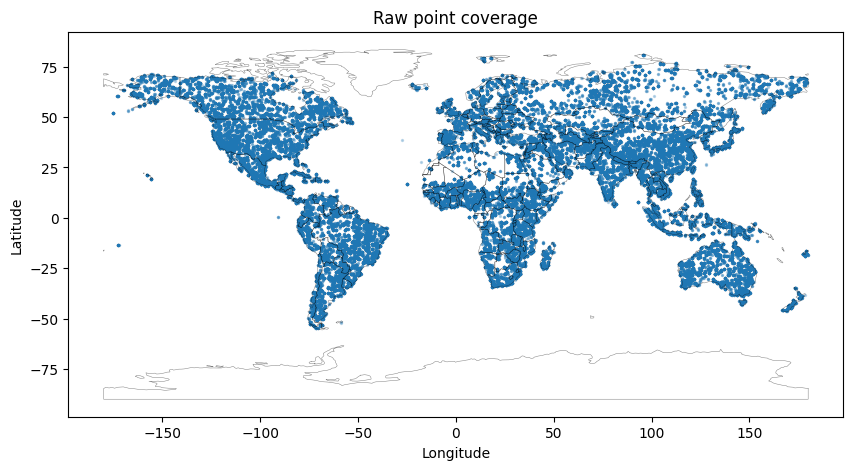

In [2]:
def resolve_data_path(path: Path) -> Path:
    candidates = [
        path,
        Path('data') / path.name,
        Path('../data') / path.name,
        Path(path.name),
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f'Could not find latent file. Tried: {[str(c) for c in candidates]}')


def payload_to_dataframe(obj) -> pd.DataFrame:
    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    if isinstance(obj, dict) and {'latents', 'meta'}.issubset(obj.keys()):
        latents = obj['latents']
        meta = obj['meta']
        if isinstance(latents, torch.Tensor):
            latents = latents.detach().cpu().numpy()
        else:
            latents = np.asarray(latents)
        if isinstance(meta, torch.Tensor):
            meta = meta.detach().cpu().numpy()
        else:
            meta = np.asarray(meta)
        if meta.ndim != 2 or meta.shape[1] < 2:
            raise ValueError(f'Expected meta with at least 2 columns (lat, lon), got shape {meta.shape}')
        if latents.shape[0] != meta.shape[0]:
            raise ValueError(f'latents/meta row mismatch: {latents.shape[0]} vs {meta.shape[0]}')
        return pd.DataFrame({'lat': meta[:, 0], 'lon': meta[:, 1], 'latent': [latents[i] for i in range(latents.shape[0])]})
    if isinstance(obj, dict) and {'lat', 'lon', 'latent'}.issubset(obj.keys()):
        return pd.DataFrame(obj)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    raise TypeError(f'Unsupported payload type from torch.load: {type(obj)}')


def to_numpy_vec(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def load_embeddings(data_path: Path = DATA_PATH, force_reload: bool = False):
    resolved = resolve_data_path(data_path)
    cache_tag = resolved.stem

    e_cache = CACHE_DIR / f'{cache_tag}_embeddings.npy'
    lat_cache = CACHE_DIR / f'{cache_tag}_lats.npy'
    lon_cache = CACHE_DIR / f'{cache_tag}_lons.npy'
    source_cache = CACHE_DIR / f'{cache_tag}_source_file.txt'

    if not force_reload and e_cache.exists() and lat_cache.exists() and lon_cache.exists():
        E = np.load(e_cache)
        lats = np.load(lat_cache)
        lons = np.load(lon_cache)
        source_file = source_cache.read_text().strip() if source_cache.exists() else str(resolved)
        return E.astype(np.float32, copy=False), lats.astype(np.float64, copy=False), lons.astype(np.float64, copy=False), source_file

    obj = torch.load(resolved, map_location='cpu', weights_only=False)
    df = payload_to_dataframe(obj)

    required_cols = {'lat', 'lon', 'latent'}
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f'Missing required columns: {missing}')

    df['lat'] = pd.to_numeric(df['lat'], errors='coerce')
    df['lon'] = pd.to_numeric(df['lon'], errors='coerce')
    df['latent'] = df['latent'].apply(to_numpy_vec)

    first_valid_idx = next((i for i, v in enumerate(df['latent'].values) if np.asarray(v).size > 0), None)
    if first_valid_idx is None:
        raise ValueError('No non-empty latent vectors found')

    d = int(np.asarray(df['latent'].iloc[first_valid_idx]).reshape(-1).shape[0])

    def normalize_shape(v):
        a = np.asarray(v).reshape(-1)
        if a.shape[0] != d:
            raise ValueError(f'Inconsistent latent dimension. Expected {d}, got {a.shape[0]}')
        return a

    df['latent'] = df['latent'].apply(normalize_shape)

    E = np.vstack(df['latent'].values).astype(np.float32, copy=False)
    lats = df['lat'].to_numpy(np.float64)
    lons = df['lon'].to_numpy(np.float64)

    if np.isnan(lats).any() or np.isnan(lons).any() or np.isnan(E).any():
        raise ValueError('Found NaNs in lat/lon/latent arrays')

    np.save(e_cache, E)
    np.save(lat_cache, lats)
    np.save(lon_cache, lons)
    source_cache.write_text(str(resolved))

    return E, lats, lons, str(resolved)


def infer_latent_file_idx(source_path: str) -> int:
    match = re.search(r'latents_(\d+)_', Path(source_path).stem)
    if match is None:
        raise ValueError(f'Could not infer latent idx from source file name: {source_path}')
    return int(match.group(1))


def resolve_geometry_results_csv(file_name: str) -> Path:
    p = Path(file_name)
    candidates = [
        p,
        Path('..') / p.name,
        Path('data') / p.name,
        Path('../data') / p.name,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f'Could not find geometry file {file_name}. Tried: {[str(c) for c in candidates]}')


def parse_geometry_array(raw, field_name: str) -> np.ndarray:
    value = ast.literal_eval(raw) if isinstance(raw, str) else raw
    arr = np.asarray(value, dtype=np.float32)
    if arr.size == 0:
        raise ValueError(f'{field_name} is empty')
    return arr


def load_geometry_transform(csv_file: str, latent_idx: int) -> dict:
    resolved = resolve_geometry_results_csv(csv_file)
    df = pd.read_csv(resolved)

    required = {'idx', 'rotation_matrix', 'translation_vec', 'lambda_vec'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'{resolved} missing required columns: {missing}')

    rows = df[df['idx'] == latent_idx]
    if rows.empty:
        raise ValueError(f'{resolved} does not contain idx={latent_idx}. Available idx values: {sorted(df["idx"].unique().tolist())}')

    row = rows.iloc[0]
    rotation_matrix = parse_geometry_array(row['rotation_matrix'], 'rotation_matrix')
    translation_vec = parse_geometry_array(row['translation_vec'], 'translation_vec')
    lambda_vec = parse_geometry_array(row['lambda_vec'], 'lambda_vec')

    if rotation_matrix.ndim != 2 or rotation_matrix.shape[0] != rotation_matrix.shape[1]:
        raise ValueError(f'rotation_matrix must be square, got shape {rotation_matrix.shape}')

    latent_dim = rotation_matrix.shape[0]
    if translation_vec.shape != (latent_dim,):
        raise ValueError(f'translation_vec shape mismatch. Expected {(latent_dim,)}, got {translation_vec.shape}')
    if lambda_vec.shape != (latent_dim,):
        raise ValueError(f'lambda_vec shape mismatch. Expected {(latent_dim,)}, got {lambda_vec.shape}')

    top2_indices = np.argsort(np.abs(lambda_vec))[::-1][:2].astype(np.int64)

    return {
        'csv_file': str(resolved),
        'rotation_matrix': rotation_matrix,
        'translation_vec': translation_vec,
        'lambda_vec': lambda_vec,
        'top2_indices': top2_indices,
    }


def project_path_with_geometry(path_indices, transform: dict) -> np.ndarray:
    idx = np.asarray(path_indices, dtype=np.int64)
    vecs = E[idx]
    centered = vecs + transform['translation_vec']
    rotated = centered @ transform['rotation_matrix']
    return rotated[:, transform['top2_indices']]


def compute_umap_projection(embeddings: np.ndarray, cache_tag: str, force_recompute: bool = False) -> np.ndarray:
    cache_path = CACHE_DIR / f'{cache_tag}_umap2d.npy'
    if not force_recompute and cache_path.exists():
        cached = np.load(cache_path)
        if cached.shape == (embeddings.shape[0], 2):
            return cached.astype(np.float32, copy=False)

    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=30,
        min_dist=0.05,
        metric='euclidean',
        random_state=42,
    )
    projected = reducer.fit_transform(embeddings)
    projected = np.asarray(projected, dtype=np.float32)
    np.save(cache_path, projected)
    return projected


E, lats, lons, source_file = load_embeddings()
DATASET_TAG = Path(source_file).stem
N, d = E.shape
print(f'Loaded file: {source_file}')
print(f'N={N:,}, d={d}')
print(f'lat range: [{lats.min():.4f}, {lats.max():.4f}] | lon range: [{lons.min():.4f}, {lons.max():.4f}]')

LATENT_FILE_IDX = infer_latent_file_idx(source_file)
GEOMETRY_TRANSFORM_FILES = {
    'H': 'H_geometry_results.csv',
    'L': 'L_geometry_results.csv',
    'Long': 'Long_geometry_results.csv',
}
GEOMETRY_TRANSFORMS = {
    name: load_geometry_transform(csv_file, LATENT_FILE_IDX)
    for name, csv_file in GEOMETRY_TRANSFORM_FILES.items()
}
UMAP_PROJECTION_2D = compute_umap_projection(E, DATASET_TAG)

print(f'Geometry transforms loaded for latent idx={LATENT_FILE_IDX}:')
for name, transform in GEOMETRY_TRANSFORMS.items():
    dims = transform['top2_indices'].tolist()
    scales = transform['lambda_vec'][transform['top2_indices']]
    print(f'  {name}: top dims={dims}, lambda={scales.tolist()}')

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(lons, lats, s=2, alpha=0.25, color='tab:blue')
draw_world_outline(ax)
ax.set_title('Raw point coverage')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

# TODO: support filtering to a geographic bounding box to work on subregions.


## 2. Pairwise Distance Indices

In [3]:
def distance_cache_path() -> Path:
    if FAISS_INDEX_MODE.lower() == 'hnsw':
        algo_tag = f"hnsw_m{FAISS_HNSW_M}_efs{FAISS_HNSW_EF_SEARCH}"
    else:
        algo_tag = 'flat'
    return CACHE_DIR / (
        f"{DATASET_TAG}_{algo_tag}_geogate_r{int(GEO_GATE_RADIUS_KM)}_"
        f"k{int(GEO_GATE_K)}_candidates_v2.npz"
    )


def latlon_to_unit_xyz(lat: np.ndarray, lon: np.ndarray) -> np.ndarray:
    lat_r = np.radians(lat)
    lon_r = np.radians(lon)
    cos_lat = np.cos(lat_r)
    x = cos_lat * np.cos(lon_r)
    y = cos_lat * np.sin(lon_r)
    z = np.sin(lat_r)
    return np.column_stack([x, y, z]).astype(np.float32, copy=False)


def build_faiss_index(vectors: np.ndarray, k_search: int):
    mode = FAISS_INDEX_MODE.lower()
    d = vectors.shape[1]

    if FAISS_NUM_THREADS > 0:
        faiss.omp_set_num_threads(int(FAISS_NUM_THREADS))

    if mode == 'hnsw':
        index = faiss.IndexHNSWFlat(d, int(FAISS_HNSW_M))
        index.hnsw.efConstruction = int(FAISS_HNSW_EF_CONSTRUCTION)
        index.hnsw.efSearch = max(int(FAISS_HNSW_EF_SEARCH), int(k_search))
        index.add(vectors)
        return index

    if mode == 'flat':
        index = faiss.IndexFlatL2(d)
        index.add(vectors)
        return index

    raise ValueError(f'Unsupported FAISS_INDEX_MODE={FAISS_INDEX_MODE!r}; expected "hnsw" or "flat"')


def batched_faiss_search(
    index,
    vectors: np.ndarray,
    k_search: int,
    batch_size: int,
    pct_start: int = 30,
    pct_end: int = 60,
):
    n = vectors.shape[0]
    sq_dists = np.empty((n, k_search), dtype=np.float32)
    nbrs = np.empty((n, k_search), dtype=np.int64)

    batch_size = max(1, int(batch_size))
    next_pct = pct_start + 5
    done = 0

    with tqdm(total=n, desc='FAISS geo-KNN search', unit='vec') as pbar:
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            d_chunk, n_chunk = index.search(vectors[start:end], k_search)
            sq_dists[start:end] = d_chunk
            nbrs[start:end] = n_chunk
            processed = end - start
            done += processed
            pbar.update(processed)

            pct = pct_start + int((done / max(n, 1)) * (pct_end - pct_start))
            while pct >= next_pct and next_pct <= pct_end:
                print(f'[Cell 2] {next_pct}% | FAISS geo search {done:,}/{n:,} vectors')
                next_pct += 5

    return sq_dists, nbrs


def compute_latent_cosine_distance(E: np.ndarray, neighbors: np.ndarray, batch_size: int) -> np.ndarray:
    n = E.shape[0]
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    E_norm = E / np.clip(norms, 1e-12, None)

    out = np.empty(neighbors.shape, dtype=np.float32)
    batch_size = max(1, int(batch_size))

    with tqdm(total=n, desc='Cosine scoring in geo gate', unit='node') as pbar:
        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            nbr = neighbors[start:end]
            sims = np.einsum('bd,bkd->bk', E_norm[start:end], E_norm[nbr], optimize=True)
            sims = np.clip(sims, -1.0, 1.0)
            dist = 1.0 - sims
            out[start:end] = np.maximum(dist, 0.0).astype(np.float32, copy=False)
            pbar.update(end - start)

    return out


def build_distance_candidates(E: np.ndarray, lats: np.ndarray, lons: np.ndarray):
    n = E.shape[0]
    k_search = min(n, int(GEO_GATE_K) + 1)
    print(f'[Cell 2] 0% | preparing geo-first FAISS ({FAISS_INDEX_MODE}) for N={n:,}, k={k_search}')

    geo_vectors = latlon_to_unit_xyz(lats, lons)
    index = build_faiss_index(geo_vectors, k_search)
    print('[Cell 2] 25% | geo index built, running batched FAISS search')

    _sq_geo, nbrs = batched_faiss_search(
        index,
        geo_vectors,
        k_search,
        FAISS_SEARCH_BATCH_SIZE,
        pct_start=30,
        pct_end=60,
    )

    latent_neighbors = nbrs[:, 1:].astype(np.int64, copy=False)
    print('[Cell 2] 70% | computing geographic distances for geo candidates')
    geo_dists = haversine_km(
        lats[:, None],
        lons[:, None],
        lats[latent_neighbors],
        lons[latent_neighbors],
    ).astype(np.float32, copy=False)

    print('[Cell 2] 85% | computing cosine-based latent distances in geo-gated candidates')
    latent_dists = compute_latent_cosine_distance(E, latent_neighbors, LATENT_SCORE_BATCH_SIZE)

    print('[Cell 2] 95% | computing tau percentile over geo-gated latent distances')
    valid_latent = latent_dists[np.isfinite(latent_dists) & (geo_dists <= GEO_GATE_RADIUS_KM)]
    if valid_latent.size == 0:
        valid_latent = latent_dists[np.isfinite(latent_dists)]
    tau = float(np.percentile(valid_latent, TAU_PERCENTILE))

    print('[Cell 2] 100% | geo-gated candidates and tau ready')
    return latent_neighbors, latent_dists, geo_dists, tau


dist_cache = distance_cache_path()
if dist_cache.exists():
    print(f'[Cell 2] 100% | cache hit: loading {dist_cache.name}')
    cached = np.load(dist_cache)
    latent_neighbors = cached['latent_neighbors']
    latent_dists = cached['latent_dists']
    geo_dists = cached['geo_dists']
    tau = float(cached['tau'])
else:
    latent_neighbors, latent_dists, geo_dists, tau = build_distance_candidates(E, lats, lons)
    np.savez_compressed(
        dist_cache,
        latent_neighbors=latent_neighbors,
        latent_dists=latent_dists,
        geo_dists=geo_dists,
        tau=np.asarray(tau, dtype=np.float32),
    )
    print(f'[Cell 2] cached candidate arrays -> {dist_cache}')

print(f'candidate_neighbors shape: {latent_neighbors.shape}')
print(f'latent_dists (1-cosine) shape: {latent_dists.shape}')
print(f'geo_dists shape: {geo_dists.shape}')
print(f'tau ({TAU_PERCENTILE}th percentile over geo gate) = {tau:.6f}')

# TODO: evaluate optional adaptive GEO_GATE_RADIUS_KM by latitude-density.


[Cell 2] 100% | cache hit: loading latents_0_92160_flat_geogate_r900_k256_candidates_v2.npz
candidate_neighbors shape: (92160, 256)
latent_dists (1-cosine) shape: (92160, 256)
geo_dists shape: (92160, 256)
tau (8th percentile over geo gate) = 0.006492


## 3. Hybrid Threshold-KNN Graph

In [4]:
def graph_param_hash() -> str:
    payload = {
        'tau_percentile': TAU_PERCENTILE,
        'tau': tau,
        'min_k_fallback': MIN_K_FALLBACK,
        'max_edges_per_node': MAX_EDGES_PER_NODE,
        'gamma': GAMMA,
        'geo_gate_radius_km': GEO_GATE_RADIUS_KM,
        'geo_gate_k': GEO_GATE_K,
        'geo_min_candidates': GEO_MIN_CANDIDATES,
        'faiss_mode': FAISS_INDEX_MODE,
        'n': int(E.shape[0]),
        'd': int(E.shape[1]),
        'numeric_stability_version': 2,
    }
    digest = hashlib.sha1(json.dumps(payload, sort_keys=True).encode('utf-8')).hexdigest()[:12]
    return digest


def build_hybrid_graph(
    latent_neighbors: np.ndarray,
    latent_dists: np.ndarray,
    geo_dists: np.ndarray,
    tau_value: float,
    gamma: float,
    min_k_fallback: int,
    max_edges_per_node: int,
):
    n = latent_neighbors.shape[0]
    g = nx.DiGraph()
    g.add_nodes_from(range(n))

    geo_fallback_nodes = 0
    latent_fallback_nodes = 0
    min_geo_keep = max(int(min_k_fallback), int(GEO_MIN_CANDIDATES))

    for i in tqdm(range(n), desc='Building geo-gated graph'):
        nbr = latent_neighbors[i]
        ld = latent_dists[i]
        gd = geo_dists[i]

        finite = np.isfinite(ld) & np.isfinite(gd)
        if not np.any(finite):
            continue

        geo_idx = np.where(finite & (gd <= GEO_GATE_RADIUS_KM))[0]
        if geo_idx.size < min_geo_keep:
            geo_fallback_nodes += 1
            finite_idx = np.where(finite)[0]
            order_geo = finite_idx[np.argsort(gd[finite_idx])]
            geo_idx = order_geo[:min(min_geo_keep, order_geo.size)]

        if geo_idx.size == 0:
            continue

        ld_geo = ld[geo_idx]
        latent_mask = ld_geo < tau_value
        if latent_mask.sum() < min_k_fallback:
            latent_fallback_nodes += 1
            chosen = np.argsort(ld_geo)[:min(int(min_k_fallback), ld_geo.size)]
            selected_idx = geo_idx[chosen]
        else:
            selected_idx = geo_idx[latent_mask]

        if selected_idx.size == 0:
            continue

        sel_nbr = nbr[selected_idx]
        sel_ld = np.maximum(ld[selected_idx], 0.0)
        sel_gd = np.maximum(gd[selected_idx], 0.0)
        weights = np.maximum(sel_ld * (1.0 + gamma * sel_gd), 0.0)

        keep = np.argsort(weights)[:max_edges_per_node]
        for pos in keep:
            j = int(sel_nbr[pos])
            g.add_edge(
                i,
                j,
                latent_dist=float(sel_ld[pos]),
                geo_dist_km=float(sel_gd[pos]),
                weight=float(weights[pos]),
            )

    return g, geo_fallback_nodes, latent_fallback_nodes


def component_labels_for_graph(g: nx.DiGraph, n_nodes: int) -> np.ndarray:
    labels = np.full(n_nodes, -1, dtype=np.int64)
    for cid, nodes in enumerate(nx.weakly_connected_components(g)):
        nodes = np.fromiter(nodes, dtype=np.int64)
        labels[nodes] = cid
    return labels


_graph_cache = CACHE_DIR / 'graph.pkl'
_param_hash = graph_param_hash()
if _graph_cache.exists():
    with _graph_cache.open('rb') as f:
        payload = pickle.load(f)
    if payload.get('param_hash') == _param_hash:
        GRAPH = payload['graph']
        geo_fallback_nodes = int(payload.get('geo_fallback_nodes', payload.get('fallback_nodes', 0)))
        latent_fallback_nodes = int(payload.get('latent_fallback_nodes', 0))
    else:
        GRAPH, geo_fallback_nodes, latent_fallback_nodes = build_hybrid_graph(
            latent_neighbors,
            latent_dists,
            geo_dists,
            tau,
            GAMMA,
            MIN_K_FALLBACK,
            MAX_EDGES_PER_NODE,
        )
        with _graph_cache.open('wb') as f:
            pickle.dump(
                {
                    'param_hash': _param_hash,
                    'graph': GRAPH,
                    'geo_fallback_nodes': geo_fallback_nodes,
                    'latent_fallback_nodes': latent_fallback_nodes,
                },
                f,
            )
else:
    GRAPH, geo_fallback_nodes, latent_fallback_nodes = build_hybrid_graph(
        latent_neighbors,
        latent_dists,
        geo_dists,
        tau,
        GAMMA,
        MIN_K_FALLBACK,
        MAX_EDGES_PER_NODE,
    )
    with _graph_cache.open('wb') as f:
        pickle.dump(
            {
                'param_hash': _param_hash,
                'graph': GRAPH,
                'geo_fallback_nodes': geo_fallback_nodes,
                'latent_fallback_nodes': latent_fallback_nodes,
            },
            f,
        )

has_negative_edge = any(
    (float(e.get('latent_dist', 0.0)) < 0.0)
    or (float(e.get('geo_dist_km', 0.0)) < 0.0)
    or (float(e.get('weight', 0.0)) < 0.0)
    for _, _, e in GRAPH.edges(data=True)
)
if has_negative_edge:
    raise ValueError('Graph integrity check failed: found negative edge values after sanitization.')

component_labels = component_labels_for_graph(GRAPH, E.shape[0])
component_sizes = sorted((len(c) for c in nx.weakly_connected_components(GRAPH)), reverse=True)

print(f'nodes={GRAPH.number_of_nodes():,}, edges={GRAPH.number_of_edges():,}')
print(f'mean edges/node={GRAPH.number_of_edges() / max(1, GRAPH.number_of_nodes()):.2f}')
print(f'geo fallback nodes={geo_fallback_nodes:,}')
print(f'latent fallback nodes={latent_fallback_nodes:,}')
print(f'connected components={len(component_sizes)}')
if len(component_sizes) > 1:
    warnings.warn('Graph has multiple connected components; cross-component pathfinding will fail.', stacklevel=2)
    print('component sizes:', component_sizes[:20], '...' if len(component_sizes) > 20 else '')

# TODO: add optional portal-edge budget for controlled long-range jumps.


nodes=92,160, edges=1,681,558
mean edges/node=18.25
geo fallback nodes=50
latent fallback nodes=47,031
connected components=16
component sizes: [59275, 32217, 356, 104, 32, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16] 


/home/micha-nowicki/repo/terramind/.venv/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3747: UserWarning: Graph has multiple connected components; cross-component pathfinding will fail.
  exec(code_obj, self.user_global_ns, self.user_ns)


# 3b. Graph Diagnostics

Negative-weight check: no negative latent_dist, geo_dist_km, or weight values found.


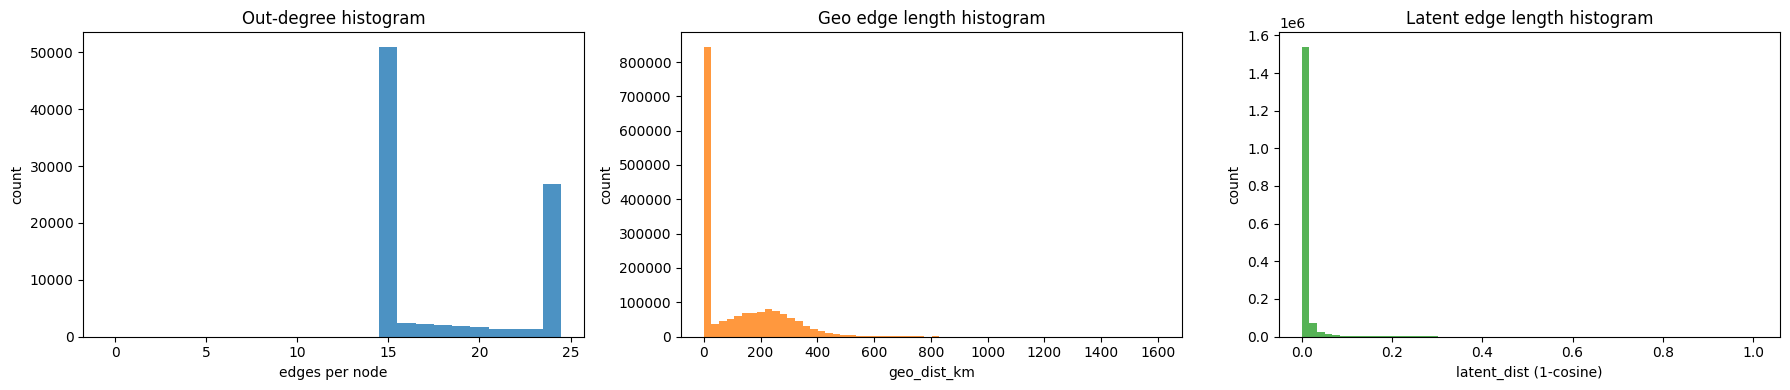

Weight decomposition over all edges: latent_base=15145.091484, geo_dist_km=195.425163, total=15147.809115


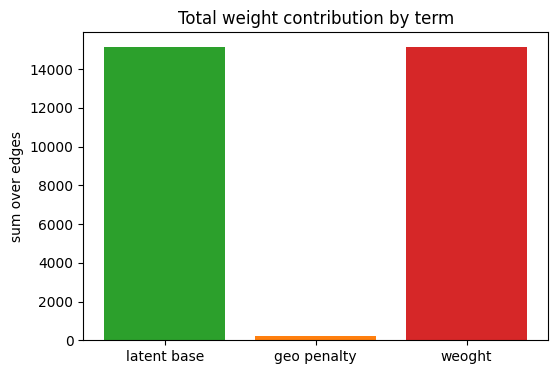

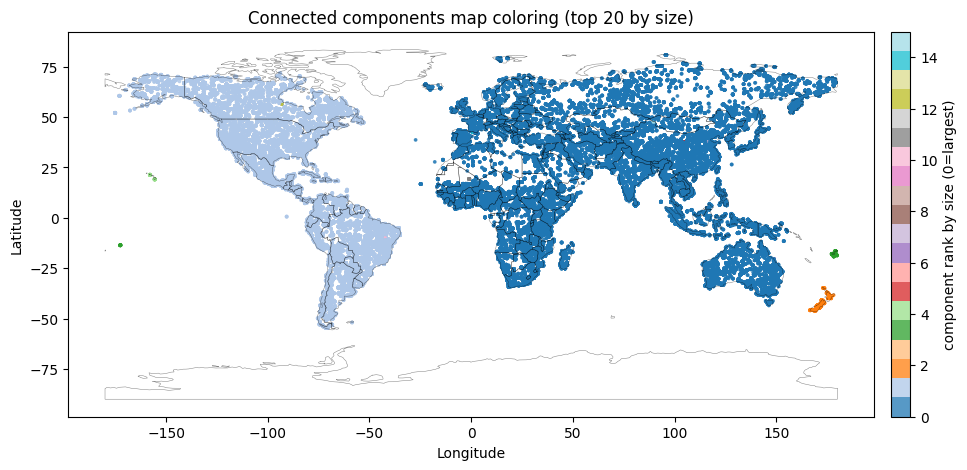

components=16, largest_component_size=59275, smallest_component_size=16


In [5]:
edge_rows = [
    (int(u), int(v), float(data.get('latent_dist', np.nan)), float(data.get('geo_dist_km', np.nan)), float(data.get('weight', np.nan)))
    for u, v, data in GRAPH.edges(data=True)
]

if not edge_rows:
    raise ValueError('GRAPH has no edges; cannot run diagnostics.')

edge_df = pd.DataFrame(edge_rows, columns=['src', 'dst', 'latent_dist', 'geo_dist_km', 'weight'])
degree_out = np.fromiter((GRAPH.out_degree(i) for i in range(GRAPH.number_of_nodes())), dtype=np.int32)

neg_mask = (edge_df[['latent_dist', 'geo_dist_km', 'weight']] < 0).any(axis=1)
neg_count = int(neg_mask.sum())
if neg_count > 0:
    warnings.warn(f'Found {neg_count} edges with negative latent/geo/weight values.', stacklevel=2)
else:
    print('Negative-weight check: no negative latent_dist, geo_dist_km, or weight values found.')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

deg_bins = np.arange(-0.5, degree_out.max() + 1.5, 1.0)
axes[0].hist(degree_out, bins=deg_bins, color='tab:blue', alpha=0.8)
axes[0].set_title('Out-degree histogram')
axes[0].set_xlabel('edges per node')
axes[0].set_ylabel('count')

axes[1].hist(edge_df['geo_dist_km'].to_numpy(np.float64), bins=60, color='tab:orange', alpha=0.8)
axes[1].set_title('Geo edge length histogram')
axes[1].set_xlabel('geo_dist_km')
axes[1].set_ylabel('count')

axes[2].hist(edge_df['latent_dist'].to_numpy(np.float64), bins=60, color='tab:green', alpha=0.8)
axes[2].set_title('Latent edge length histogram')
axes[2].set_xlabel('latent_dist (1-cosine)')
axes[2].set_ylabel('count')

fig.tight_layout()
plt.show()

latent_base_total = float(edge_df['latent_dist'].sum())
geo_gamma_total = float((edge_df['geo_dist_km']).sum()) * GAMMA
total_weight = float(edge_df['weight'].sum())

print(f'Weight decomposition over all edges: latent_base={latent_base_total:.6f}, geo_dist_km={geo_gamma_total:.6f}, total={total_weight:.6f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['latent base', 'geo penalty', 'weoght'], [latent_base_total, geo_gamma_total, total_weight], color=['tab:green', 'tab:orange', 'tab:red'])
ax.set_title('Total weight contribution by term')
ax.set_ylabel('sum over edges')
plt.show()

labels = component_labels.astype(np.int64, copy=False)
uniq, counts = np.unique(labels, return_counts=True)
order = uniq[np.argsort(counts)[::-1]]
top_k = min(20, order.size)

mapped = np.full(labels.shape, -1, dtype=np.int32)
for rank, cid in enumerate(order[:top_k]):
    mapped[labels == cid] = int(rank)

fig, ax = plt.subplots(figsize=(11, 5))
other_mask = mapped < 0
if np.any(other_mask):
    ax.scatter(lons[other_mask], lats[other_mask], s=2, c='lightgray', alpha=0.2, label='other components')

main_mask = mapped >= 0
if np.any(main_mask):
    sc = ax.scatter(
        lons[main_mask],
        lats[main_mask],
        s=3,
        c=mapped[main_mask],
        cmap='tab20',
        alpha=0.75,
        vmin=0,
        vmax=max(top_k - 1, 1),
    )
    cbar = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label('component rank by size (0=largest)')

draw_world_outline(ax)
ax.set_title('Connected components map coloring (top 20 by size)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

print(f'components={len(uniq)}, largest_component_size={int(counts.max()) if counts.size else 0}, smallest_component_size={int(counts.min()) if counts.size else 0}')


## 4. Geodesic Path Computation

In [6]:
if N_SHORTEST_PATHS > 3:
    warnings.warn("Yen's K-shortest paths can be slow when N_SHORTEST_PATHS > 3.", stacklevel=2)


def nearest_index_by_geo(lat: float, lon: float) -> int:
    d = haversine_km(lat, lon, lats, lons)
    return int(np.argmin(d))


def baseline_geodesic_indices(source_idx: int, target_idx: int, steps: int = CORRIDOR_BASELINE_STEPS) -> list[int]:
    lat1, lon1 = float(lats[source_idx]), float(lons[source_idx])
    lat2, lon2 = float(lats[target_idx]), float(lons[target_idx])
    line_lats = np.linspace(lat1, lat2, steps)
    line_lons = np.linspace(lon1, lon2, steps)
    idxs = [nearest_index_by_geo(la, lo) for la, lo in zip(line_lats, line_lons)]
    out = []
    for idx in idxs:
        if not out or idx != out[-1]:
            out.append(idx)
    return out


def corridor_mask_from_baseline(baseline_indices: list[int], corridor_width_km: float):
    if corridor_width_km <= 0:
        return np.ones(E.shape[0], dtype=bool), np.zeros(E.shape[0], dtype=np.float32)

    unique_baseline = np.unique(np.asarray(baseline_indices, dtype=np.int64))
    min_dist = np.full(E.shape[0], np.inf, dtype=np.float64)

    for idx in unique_baseline:
        d = haversine_km(lats[idx], lons[idx], lats, lons)
        min_dist = np.minimum(min_dist, d)

    return min_dist <= corridor_width_km, min_dist.astype(np.float32)


def induced_corridor_graph(
    graph: nx.DiGraph,
    source_idx: int,
    target_idx: int,
    baseline_indices: list[int],
    corridor_width_km: float,
):
    mask, min_dist = corridor_mask_from_baseline(baseline_indices, corridor_width_km)
    mask[source_idx] = True
    mask[target_idx] = True

    corridor_nodes = np.where(mask)[0]
    subgraph = graph.subgraph(corridor_nodes).copy()

    if not subgraph.has_node(source_idx) or not subgraph.has_node(target_idx):
        raise ValueError('Source/target not present in corridor subgraph; increase CORRIDOR_WIDTH_KM.')

    if not nx.has_path(subgraph, source_idx, target_idx):
        raise ValueError('No path inside corridor. Increase CORRIDOR_WIDTH_KM or relax geo-gate parameters.')

    return subgraph, mask, min_dist


def path_decomposition(g: nx.DiGraph, path: list[int]) -> dict[str, np.ndarray]:
    latent = []
    geo = []
    weight = []
    for a, b in zip(path[:-1], path[1:]):
        e = g[a][b]
        latent.append(float(e['latent_dist']))
        geo.append(float(e['geo_dist_km']))
        weight.append(float(e['weight']))
    return {
        'latent': np.asarray(latent, dtype=np.float64),
        'geo_km': np.asarray(geo, dtype=np.float64),
        'weight': np.asarray(weight, dtype=np.float64),
    }


def path_geo_length_km(path: list[int]) -> float:
    if len(path) < 2:
        return 0.0
    seg = haversine_km(lats[path[:-1]], lons[path[:-1]], lats[path[1:]], lons[path[1:]])
    return float(np.sum(seg))


def find_geodesic_path(
    graph: nx.DiGraph,
    source_idx: int,
    target_idx: int,
    n_paths: int = N_SHORTEST_PATHS,
    comp_labels: np.ndarray | None = None,
    use_corridor: bool = CORRIDOR_ENABLED,
    corridor_width_km: float = CORRIDOR_WIDTH_KM,
    corridor_steps: int = CORRIDOR_BASELINE_STEPS,
):
    if comp_labels is None:
        comp_labels = component_labels_for_graph(graph, graph.number_of_nodes())

    if comp_labels[source_idx] != comp_labels[target_idx]:
        raise ValueError(
            'Source and target are in different components. Lower tau or increase MIN_K_FALLBACK and rebuild graph.'
        )

    baseline = baseline_geodesic_indices(source_idx, target_idx, steps=corridor_steps)
    search_graph = graph
    corridor_mask = None

    if use_corridor:
        search_graph, corridor_mask, _min_dist = induced_corridor_graph(
            graph,
            source_idx,
            target_idx,
            baseline,
            corridor_width_km,
        )

    if not nx.has_path(search_graph, source_idx, target_idx):
        raise ValueError(
            'No directed path between source and target in current graph. '
            'Increase MAX_EDGES_PER_NODE or relax geo/latent gating parameters.'
        )

    primary = nx.dijkstra_path(search_graph, source_idx, target_idx, weight='weight')

    paths = []
    for k, p in enumerate(nx.shortest_simple_paths(search_graph, source_idx, target_idx, weight='weight')):
        paths.append(p)
        if k + 1 >= n_paths:
            break

    if not paths:
        paths = [primary]

    direct_geo = float(haversine_km(lats[source_idx], lons[source_idx], lats[target_idx], lons[target_idx]))

    path_payload = []
    for p in paths:
        decomp = path_decomposition(search_graph, p)
        total_weight = float(np.sum(decomp['weight']))
        geo_len = path_geo_length_km(p)
        detour = geo_len / max(direct_geo, 1e-9)
        path_payload.append(
            {
                'indices': p,
                'total_weight': total_weight,
                'geo_length_km': geo_len,
                'detour_ratio': float(detour),
                'decomposition': decomp,
            }
        )

    corridor_node_count = int(np.sum(corridor_mask)) if corridor_mask is not None else int(graph.number_of_nodes())

    return {
        'source_idx': int(source_idx),
        'target_idx': int(target_idx),
        'baseline_indices': baseline,
        'direct_geo_km': direct_geo,
        'corridor': {
            'enabled': bool(use_corridor),
            'width_km': float(corridor_width_km),
            'node_count': corridor_node_count,
        },
        'paths': path_payload,
    }


source_idx = 0
target_idx = 1 if E.shape[0] > 1 else 0
path_result = None

print(
    f'Default source_idx={source_idx}, target_idx={target_idx} | '
    f'corridor_enabled={CORRIDOR_ENABLED}, corridor_width_km={CORRIDOR_WIDTH_KM}'
)
# path_result = find_geodesic_path(GRAPH, source_idx, target_idx, N_SHORTEST_PATHS, component_labels)

# TODO: implement optional bidirectional Dijkstra in corridor graph for faster repeated queries.


Default source_idx=0, target_idx=1 | corridor_enabled=False, corridor_width_km=1000.0


/home/micha-nowicki/repo/terramind/.venv/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3747: UserWarning: Yen's K-shortest paths can be slow when N_SHORTEST_PATHS > 3.
  exec(code_obj, self.user_global_ns, self.user_ns)


## 5. Interactive Point Picker

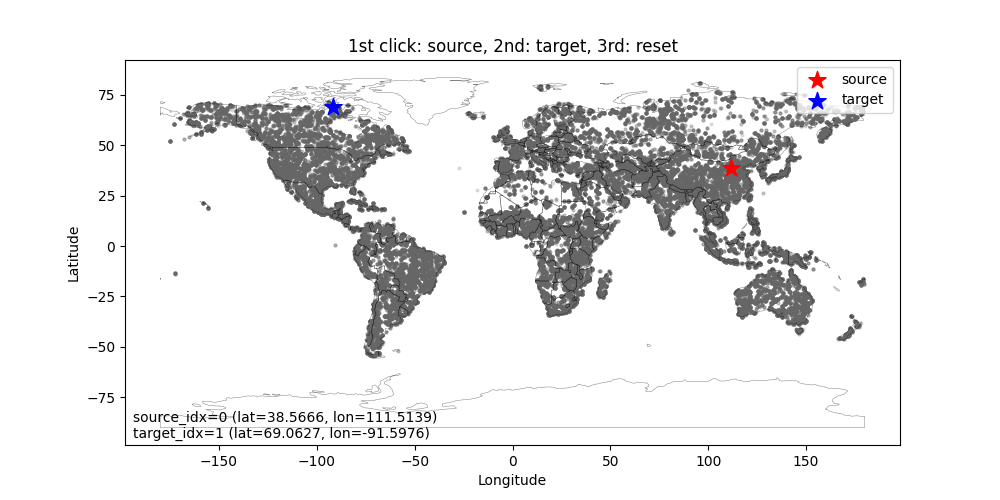

Button(button_style='primary', description='Compute Path', style=ButtonStyle())

In [7]:
def launch_point_picker():
    global source_idx, target_idx, path_result

    backend = activate_interactive_backend()
    if backend == 'inline':
        warnings.warn('Point picker is static because interactive backend is unavailable.', stacklevel=2)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(lons, lats, s=4, alpha=0.18, color='0.4')
    draw_world_outline(ax)

    src_marker = ax.scatter([], [], marker='*', s=170, color='red', label='source')
    tgt_marker = ax.scatter([], [], marker='*', s=170, color='blue', label='target')
    status_text = ax.text(0.01, 0.01, '', transform=ax.transAxes, va='bottom', ha='left')

    ax.set_title('1st click: source, 2nd: target, 3rd: reset')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend(loc='upper right')

    click_state = {'count': 0}

    def update_status():
        status_text.set_text(
            f'source_idx={source_idx} (lat={lats[source_idx]:.4f}, lon={lons[source_idx]:.4f})\n'
            f'target_idx={target_idx} (lat={lats[target_idx]:.4f}, lon={lons[target_idx]:.4f})'
        )

    def set_markers():
        src_marker.set_offsets(np.array([[lons[source_idx], lats[source_idx]]]))
        tgt_marker.set_offsets(np.array([[lons[target_idx], lats[target_idx]]]))

    def on_click(event):
        global source_idx, target_idx
        if event.inaxes != ax or event.xdata is None or event.ydata is None:
            return

        idx = nearest_index_by_geo(float(event.ydata), float(event.xdata))
        state = click_state['count'] % 3

        if state == 0:
            source_idx = idx
        elif state == 1:
            target_idx = idx
        else:
            source_idx = idx
            target_idx = idx

        click_state['count'] += 1
        set_markers()
        update_status()
        fig.canvas.draw_idle()
        print(f'Click selected idx={idx}, lat={lats[idx]:.4f}, lon={lons[idx]:.4f}')

    def compute_path(_):
        global path_result
        path_result = find_geodesic_path(GRAPH, source_idx, target_idx, N_SHORTEST_PATHS, component_labels)
        print(
            f'Computed {len(path_result["paths"])} path(s). '
            f'Best detour={path_result["paths"][0]["detour_ratio"]:.3f}'
        )

    set_markers()
    update_status()
    fig.canvas.mpl_connect('button_press_event', on_click)
    plt.show()

    if widgets is not None:
        btn = widgets.Button(description='Compute Path', button_style='primary')
        btn.on_click(compute_path)
        display(btn)
    else:
        print('ipywidgets unavailable; call find_geodesic_path(...) manually.')

    return fig, ax


picker_fig, picker_ax = launch_point_picker()

# TODO: add lasso selection for source/target regions with embedding averaging.

## 6. Path Map & Profile

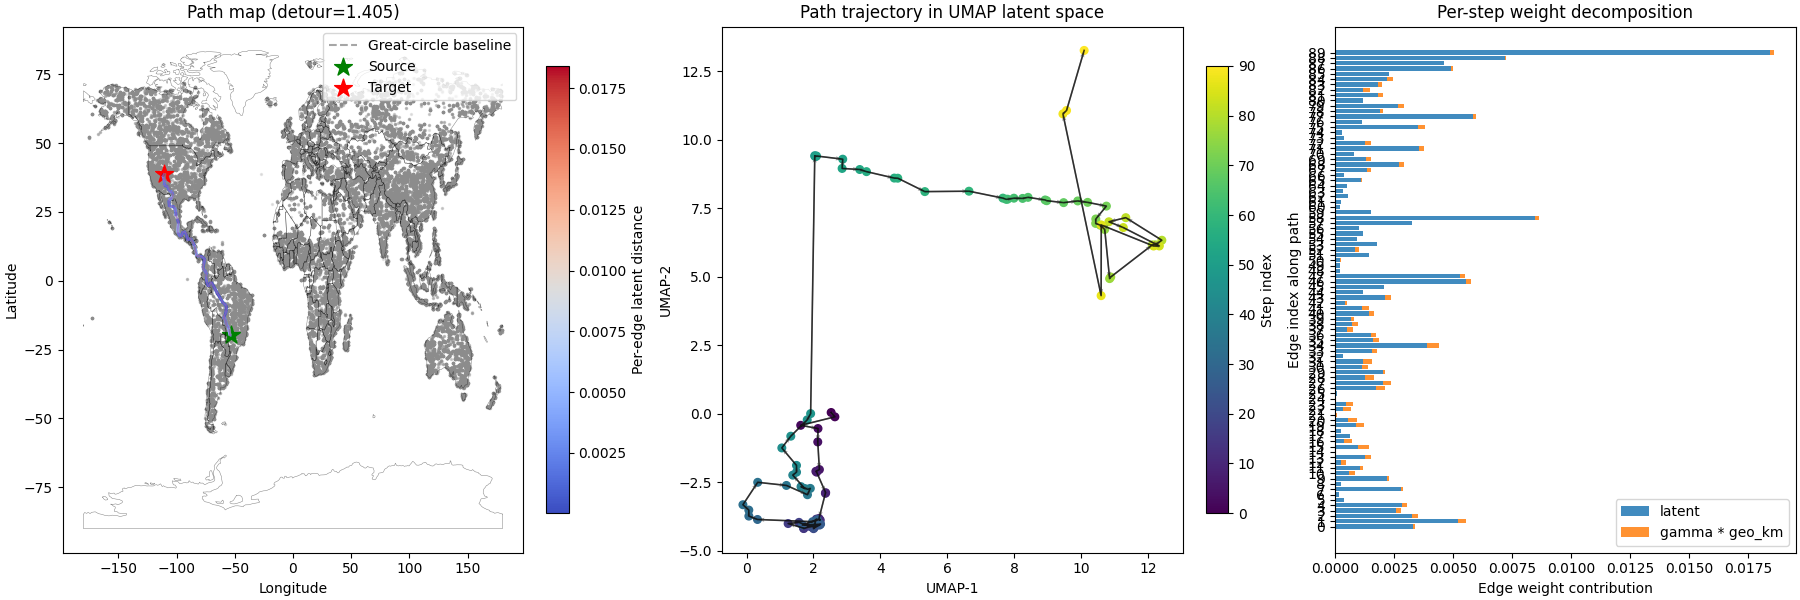

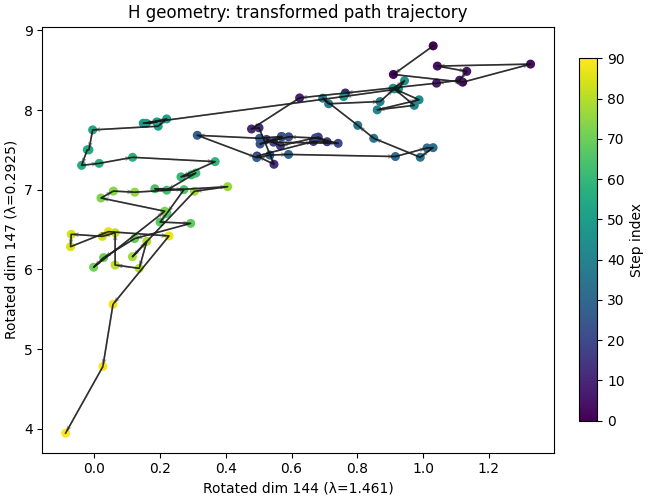

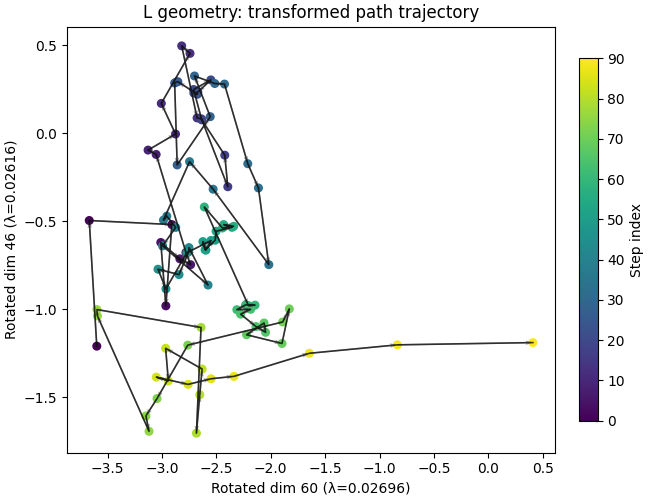

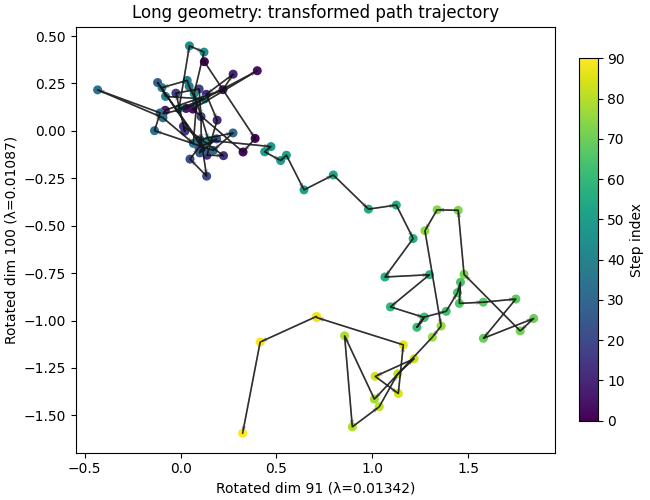

In [9]:
def _plot_step_trajectory(ax, coords_2d: np.ndarray):
    ax.plot(coords_2d[:, 0], coords_2d[:, 1], color='black', linewidth=1.2, alpha=0.7)
    sc = ax.scatter(coords_2d[:, 0], coords_2d[:, 1], c=np.arange(len(coords_2d)), cmap='viridis', s=30)
    if len(coords_2d) >= 2:
        delta = coords_2d[1:] - coords_2d[:-1]
        ax.quiver(
            coords_2d[:-1, 0],
            coords_2d[:-1, 1],
            delta[:, 0],
            delta[:, 1],
            angles='xy',
            scale_units='xy',
            scale=1,
            color='0.3',
            alpha=0.55,
            width=0.003,
        )
    return sc


def plot_path_result(path_result: dict, path_rank: int = 0):
    global latest_geometry_figures

    if path_result is None:
        raise ValueError('path_result is None. Compute a path first (Cell Group 5).')

    paths = path_result['paths']
    if not paths:
        raise ValueError('No paths found in path_result')

    path_rank = int(np.clip(path_rank, 0, len(paths) - 1))
    selected = paths[path_rank]
    path = selected['indices']
    decomp = selected['decomposition']

    fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, constrained_layout=True)
    ax_map, ax_latent, ax_bars = axes

    # Panel 1: geographic path map.
    ax_map.scatter(lons, lats, s=2, alpha=0.2, color='0.55')
    draw_world_outline(ax_map)

    if len(path) >= 2:
        segments = [
            [[lons[a], lats[a]], [lons[b], lats[b]]]
            for a, b in zip(path[:-1], path[1:])
        ]
        lc = LineCollection(
            segments,
            cmap='coolwarm',
            norm=Normalize(vmin=float(np.min(decomp['latent'])), vmax=float(np.max(decomp['latent']) + 1e-9)),
            linewidths=2.2,
        )
        lc.set_array(decomp['latent'])
        ax_map.add_collection(lc)
        fig.colorbar(lc, ax=ax_map, shrink=0.85, label='Per-edge latent distance')

    baseline = path_result['baseline_indices']
    if len(baseline) >= 2:
        ax_map.plot(lons[baseline], lats[baseline], '--', color='gray', alpha=0.7, linewidth=1.5, label='Great-circle baseline')

    src = path_result['source_idx']
    tgt = path_result['target_idx']
    ax_map.scatter([lons[src]], [lats[src]], marker='*', s=180, color='green', label='Source')
    ax_map.scatter([lons[tgt]], [lats[tgt]], marker='*', s=180, color='red', label='Target')

    if len(paths) > 1:
        for alt in paths[1:]:
            p = alt['indices']
            ax_map.plot(lons[p], lats[p], color='tab:purple', alpha=0.25, linewidth=1.0)

    ax_map.set_title(f'Path map (detour={selected["detour_ratio"]:.3f})')
    ax_map.set_xlabel('Longitude')
    ax_map.set_ylabel('Latitude')
    ax_map.legend(loc='upper right')

    # Panel 2: UMAP latent trajectory.
    pxy = UMAP_PROJECTION_2D[np.asarray(path, dtype=np.int64)]
    sc = _plot_step_trajectory(ax_latent, pxy)
    fig.colorbar(sc, ax=ax_latent, shrink=0.85, label='Step index')
    ax_latent.set_title('Path trajectory in UMAP latent space')
    ax_latent.set_xlabel('UMAP-1')
    ax_latent.set_ylabel('UMAP-2')

    # Panel 3: per-step latent + geographic weight split.
    latent_part = decomp['latent']
    geo_part = GAMMA * decomp['geo_km']
    y = np.arange(len(latent_part))
    ax_bars.barh(y, latent_part, color='tab:blue', alpha=0.85, label='latent')
    ax_bars.barh(y, geo_part, left=latent_part, color='tab:orange', alpha=0.85, label='gamma * geo_km')
    ax_bars.set_yticks(y)
    ax_bars.set_yticklabels([str(i) for i in y])
    ax_bars.set_xlabel('Edge weight contribution')
    ax_bars.set_ylabel('Edge index along path')
    ax_bars.set_title('Per-step weight decomposition')
    ax_bars.legend(loc='lower right')

    plt.show()

    latest_geometry_figures = {}
    for name, transform in GEOMETRY_TRANSFORMS.items():
        gfig, gax = plt.subplots(figsize=(6.5, 5.0), constrained_layout=True)
        transformed_path = project_path_with_geometry(path, transform)
        gsc = _plot_step_trajectory(gax, transformed_path)
        gfig.colorbar(gsc, ax=gax, shrink=0.85, label='Step index')

        top2 = transform['top2_indices']
        scales = transform['lambda_vec'][top2]
        gax.set_title(f'{name} geometry: transformed path trajectory')
        gax.set_xlabel(f'Rotated dim {int(top2[0])} (λ={float(scales[0]):.4g})')
        gax.set_ylabel(f'Rotated dim {int(top2[1])} (λ={float(scales[1]):.4g})')

        plt.show()
        latest_geometry_figures[name] = gfig

    return fig


latest_path_figure = None
latest_geometry_figures = {}
if path_result is not None:
    latest_path_figure = plot_path_result(path_result)

# TODO: animate traversal step-by-step on the map panel.


## 7. γ and τ Sweep

In [ ]:
def graph_summary(g: nx.DiGraph, geo_fallback_nodes: int, latent_fallback_nodes: int) -> dict[str, float]:
    comps = list(nx.weakly_connected_components(g))
    return {
        'mean_edges_per_node': g.number_of_edges() / max(1, g.number_of_nodes()),
        'geo_fallback_nodes': float(geo_fallback_nodes),
        'latent_fallback_nodes': float(latent_fallback_nodes),
        'components': float(len(comps)),
    }


def sweep_hyperparameters(
    source_idx: int,
    target_idx: int,
    gamma_values: np.ndarray = GAMMA_SWEEP,
    tau_percentiles: tuple[int, ...] = TAU_SWEEP_PERCENTILES,
):
    gamma_rows = []
    for gamma in tqdm(gamma_values, desc='Gamma sweep'):
        g, geo_fallback, latent_fallback = build_hybrid_graph(
            latent_neighbors, latent_dists, geo_dists, tau, float(gamma), MIN_K_FALLBACK, MAX_EDGES_PER_NODE
        )
        labels = component_labels_for_graph(g, E.shape[0])
        summary = graph_summary(g, geo_fallback, latent_fallback)
        try:
            r = find_geodesic_path(g, source_idx, target_idx, n_paths=1, comp_labels=labels)
            detour = r['paths'][0]['detour_ratio']
            path_steps = len(r['paths'][0]['indices']) - 1
            total_w = r['paths'][0]['total_weight']
        except Exception:
            detour, path_steps, total_w = np.nan, np.nan, np.nan
        gamma_rows.append(
            {
                'gamma': float(gamma),
                'detour_ratio': detour,
                'path_steps': path_steps,
                'total_path_weight': total_w,
                **summary,
            }
        )

    tau_rows = []
    flat_latent = latent_dists[np.isfinite(latent_dists) & (geo_dists <= GEO_GATE_RADIUS_KM)]
    if flat_latent.size == 0:
        flat_latent = latent_dists[np.isfinite(latent_dists)]

    for pct in tqdm(tau_percentiles, desc='Tau sweep'):
        tau_local = float(np.percentile(flat_latent, pct))
        g, geo_fallback, latent_fallback = build_hybrid_graph(
            latent_neighbors, latent_dists, geo_dists, tau_local, GAMMA, MIN_K_FALLBACK, MAX_EDGES_PER_NODE
        )
        labels = component_labels_for_graph(g, E.shape[0])
        summary = graph_summary(g, geo_fallback, latent_fallback)
        try:
            r = find_geodesic_path(g, source_idx, target_idx, n_paths=1, comp_labels=labels)
            detour = r['paths'][0]['detour_ratio']
        except Exception:
            detour = np.nan
        tau_rows.append(
            {
                'tau_percentile': int(pct),
                'tau_value': tau_local,
                'detour_ratio': detour,
                **summary,
            }
        )

    gamma_df = pd.DataFrame(gamma_rows)
    tau_df = pd.DataFrame(tau_rows)

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(gamma_df['gamma'], gamma_df['detour_ratio'], marker='o')
    ax.set_xscale('log')
    ax.set_xlabel('gamma (log scale)')
    ax.set_ylabel('detour ratio')
    ax.set_title('Detour ratio vs gamma')
    ax.grid(True, alpha=0.3)
    plt.show()

    display(tau_df)
    return gamma_df, tau_df


if E.shape[0] > 50_000:
    print('Large N detected: sweeps may be slow. Start with fewer gamma values.')

# gamma_sweep_df, tau_sweep_df = sweep_hyperparameters(source_idx, target_idx)

# TODO: add ipywidgets sliders for live gamma recomputation and redraw.


## 8. Detour Ratio Heatmap

In [ ]:
def detour_ratio_heatmap(graph: nx.DiGraph, comp_labels: np.ndarray, r: int = RANDOM_PAIR_SAMPLES, seed: int = 0):
    rng = np.random.default_rng(seed)
    mids_lat = []
    mids_lon = []
    detours = []

    attempts = 0
    max_attempts = max(10 * r, 1000)
    while len(detours) < r and attempts < max_attempts:
        attempts += 1
        a, b = rng.integers(0, E.shape[0], size=2)
        if a == b or comp_labels[a] != comp_labels[b]:
            continue
        try:
            res = find_geodesic_path(graph, int(a), int(b), n_paths=1, comp_labels=comp_labels)
        except Exception:
            continue
        det = res['paths'][0]['detour_ratio']
        mids_lat.append(float((lats[a] + lats[b]) / 2.0))
        mids_lon.append(float((lons[a] + lons[b]) / 2.0))
        detours.append(float(det))

    if not detours:
        raise ValueError('No valid sampled pairs for detour heatmap')

    mids_lat = np.asarray(mids_lat)
    mids_lon = np.asarray(mids_lon)
    detours = np.asarray(detours)

    xi = np.linspace(lons.min(), lons.max(), 220)
    yi = np.linspace(lats.min(), lats.max(), 120)
    gx, gy = np.meshgrid(xi, yi)
    gz = griddata((mids_lon, mids_lat), detours, (gx, gy), method='linear')

    fig, ax = plt.subplots(figsize=(12, 5))
    hm = ax.pcolormesh(gx, gy, gz, cmap='magma', shading='auto')
    draw_world_outline(ax)
    ax.scatter(mids_lon, mids_lat, s=8, c=detours, cmap='magma', alpha=0.35)
    ax.set_title(f'Detour ratio heatmap from {len(detours)} sampled pairs')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    fig.colorbar(hm, ax=ax, label='Detour ratio')
    plt.show()

    sampled = pd.DataFrame({'mid_lat': mids_lat, 'mid_lon': mids_lon, 'detour_ratio': detours})
    return sampled, fig


# detour_samples_df, detour_heatmap_fig = detour_ratio_heatmap(GRAPH, component_labels, r=RANDOM_PAIR_SAMPLES)

# TODO: stratify random pair sampling by biome/elevation to reduce regional bias.

## 9. Save Results

In [ ]:
def save_results(path_result: dict, graph: nx.DiGraph):
    if path_result is None:
        raise ValueError('No path_result found. Compute a path first.')

    src = path_result['source_idx']
    tgt = path_result['target_idx']
    best = path_result['paths'][0]
    p = best['indices']
    dec = best['decomposition']

    tag = f'src{src}_tgt{tgt}_lat{lats[src]:+07.3f}_lon{lons[src]:+08.3f}_lat{lats[tgt]:+07.3f}_lon{lons[tgt]:+08.3f}'.replace('.', 'p')

    rows = []
    for k, (a, b) in enumerate(zip(p[:-1], p[1:])):
        rows.append(
            {
                'step': k,
                'src_idx': int(a),
                'dst_idx': int(b),
                'src_lat': float(lats[a]),
                'src_lon': float(lons[a]),
                'dst_lat': float(lats[b]),
                'dst_lon': float(lons[b]),
                'latent_dist': float(dec['latent'][k]),
                'geo_dist_km': float(dec['geo_km'][k]),
                'weight': float(dec['weight'][k]),
            }
        )

    edges_df = pd.DataFrame(rows)
    csv_path = EXPORT_DIR / f'path_edges_{tag}.csv'
    edges_df.to_csv(csv_path, index=False)

    figs = {}
    if 'latest_path_figure' in globals() and latest_path_figure is not None:
        fig_path = EXPORT_DIR / f'path_map_profile_{tag}.png'
        latest_path_figure.savefig(fig_path, dpi=300)
        figs['path_map_profile'] = str(fig_path)

    if 'latest_geometry_figures' in globals() and latest_geometry_figures:
        for name, fig in latest_geometry_figures.items():
            if fig is None:
                continue
            geometry_fig_path = EXPORT_DIR / f'path_geometry_{name}_{tag}.png'
            fig.savefig(geometry_fig_path, dpi=300)
            figs[f'path_geometry_{name}'] = str(geometry_fig_path)

    graph_hash = graph_param_hash()
    graph_path = CACHE_DIR / f'graph_{graph_hash}.pkl'
    with graph_path.open('wb') as f:
        pickle.dump({'graph': graph, 'param_hash': graph_hash}, f)

    print(f'Saved edge CSV: {csv_path}')
    for key, value in figs.items():
        print(f'Saved figure ({key}): {value}')
    print(f'Saved graph cache: {graph_path}')

    return {
        'csv': str(csv_path),
        'figures': figs,
        'graph': str(graph_path),
    }


# save_payload = save_results(path_result, GRAPH)

# TODO: export best path as GeoJSON LineString for GIS tools.
